In [2]:
from __future__ import print_function
import torch.utils.data as data
from PIL import Image
import os
import os.path
import errno
import numpy as np
import torch
import codecs


class MovingMNIST(data.Dataset):
    """`MovingMNIST <http://www.cs.toronto.edu/~nitish/unsupervised_video/>`_ Dataset.

    Args:
        root (string): Root directory of dataset where ``processed/training.pt``
            and  ``processed/test.pt`` exist.
        train (bool, optional): If True, creates dataset from ``training.pt``,
            otherwise from ``test.pt``.
        split (int, optional): Train/test split size. Number defines how many samples
            belong to test set.
        download (bool, optional): If true, downloads the dataset from the internet and
            puts it in root directory. If dataset is already downloaded, it is not
            downloaded again.
        transform (callable, optional): A function/transform that takes in an PIL image
            and returns a transformed version. E.g, ``transforms.RandomCrop``
        target_transform (callable, optional): A function/transform that takes in an PIL
            image and returns a transformed version. E.g, ``transforms.RandomCrop``
    """
    urls = [
        'https://github.com/tychovdo/MovingMNIST/raw/master/mnist_test_seq.npy.gz'
    ]
    raw_folder = 'raw'
    processed_folder = 'processed'
    training_file = 'moving_mnist_train.pt'
    test_file = 'moving_mnist_test.pt'

    def __init__(self, root, train=True, split=1000, transform=None, target_transform=None, download=False):
        self.root = os.path.expanduser(root)
        self.transform = transform
        self.target_transform = target_transform
        self.split = split
        self.train = train  # training set or test set

        if download:
            self.download()

        if not self._check_exists():
            raise RuntimeError('Dataset not found.' +
                               ' You can use download=True to download it')

        if self.train:
            self.train_data = torch.load(
                os.path.join(self.root, self.processed_folder, self.training_file))
        else:
            self.test_data = torch.load(
                os.path.join(self.root, self.processed_folder, self.test_file))

    def __getitem__(self, index):
        """
        Args:
            index (int): Index

        Returns:
            tuple: (seq, target) where sampled sequences are splitted into a seq
                    and target part
        """

        # need to iterate over time
        def _transform_time(data):
            new_data = None
            for i in range(data.size(0)):
                img = Image.fromarray(data[i].numpy(), mode='L')
                new_data = self.transform(img) if new_data is None else torch.cat([self.transform(img), new_data], dim=0)
            return new_data

        if self.train:
            seq, target = self.train_data[index, :10], self.train_data[index, 10:]
        else:
            seq, target = self.test_data[index, :10], self.test_data[index, 10:]

        if self.transform is not None:
            seq = _transform_time(seq)
        if self.target_transform is not None:
            target = _transform_time(target)

        return seq, target

    def __len__(self):
        if self.train:
            return len(self.train_data)
        else:
            return len(self.test_data)

    def _check_exists(self):
        return os.path.exists(os.path.join(self.root, self.processed_folder, self.training_file)) and \
            os.path.exists(os.path.join(self.root, self.processed_folder, self.test_file))

    def download(self):
        """Download the Moving MNIST data if it doesn't exist in processed_folder already."""
        from six.moves import urllib
        import gzip

        if self._check_exists():
            return

        # download files
        try:
            os.makedirs(os.path.join(self.root, self.raw_folder))
            os.makedirs(os.path.join(self.root, self.processed_folder))
        except OSError as e:
            if e.errno == errno.EEXIST:
                pass
            else:
                raise

        for url in self.urls:
            print('Downloading ' + url)
            data = urllib.request.urlopen(url)
            filename = url.rpartition('/')[2]
            file_path = os.path.join(self.root, self.raw_folder, filename)
            with open(file_path, 'wb') as f:
                f.write(data.read())
            with open(file_path.replace('.gz', ''), 'wb') as out_f, \
                    gzip.GzipFile(file_path) as zip_f:
                out_f.write(zip_f.read())
            os.unlink(file_path)

        # process and save as torch files
        print('Processing...')

        training_set = torch.from_numpy(
            np.load(os.path.join(self.root, self.raw_folder, 'mnist_test_seq.npy')).swapaxes(0, 1)[:-self.split]
        )
        test_set = torch.from_numpy(
            np.load(os.path.join(self.root, self.raw_folder, 'mnist_test_seq.npy')).swapaxes(0, 1)[-self.split:]
        )

        with open(os.path.join(self.root, self.processed_folder, self.training_file), 'wb') as f:
            torch.save(training_set, f)
        with open(os.path.join(self.root, self.processed_folder, self.test_file), 'wb') as f:
            torch.save(test_set, f)

        print('Done!')

    def __repr__(self):
        fmt_str = 'Dataset ' + self.__class__.__name__ + '\n'
        fmt_str += '    Number of datapoints: {}\n'.format(self.__len__())
        tmp = 'train' if self.train is True else 'test'
        fmt_str += '    Train/test: {}\n'.format(tmp)
        fmt_str += '    Root Location: {}\n'.format(self.root)
        tmp = '    Transforms (if any): '
        fmt_str += '{0}{1}\n'.format(tmp, self.transform.__repr__().replace('\n', '\n' + ' ' * len(tmp)))
        tmp = '    Target Transforms (if any): '
        fmt_str += '{0}{1}'.format(tmp, self.target_transform.__repr__().replace('\n', '\n' + ' ' * len(tmp)))
        return fmt_str

In [31]:
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from easydict import EasyDict
from tqdm.notebook import tqdm

In [14]:
# 설정
args = EasyDict({
    'batch_size': 128,
    'device': torch.device('cuda' if torch.cuda.is_available() else 'cpu'),
    'input_size': 4096,
    'hidden_size': 2048,
    'output_size': 4096,
    'num_layers': 2,
    'learning_rate': 0.0005,
    'max_iter': 10000
})

In [5]:
train_set = MovingMNIST(
    root='./data/mnist',
    train=True,
    download=True,
    transform=transforms.ToTensor(),
    target_transform=transforms.ToTensor()
)

test_set = MovingMNIST(
    root='./data/mnist',
    train=False,
    download=True,
    transform=transforms.ToTensor(),
    target_transform=transforms.ToTensor()
)

Processing...
Done!


In [15]:
train_loader = DataLoader(dataset=train_set,
                          batch_size=args.batch_size,
                          shuffle=True)

test_loader = DataLoader(dataset=test_set,
                         batch_size=args.batch_size,
                         shuffle=False)

In [22]:
x = next(iter(train_loader))
print(x[0].shape)
print(x[1].shape)

/tmp/ipykernel_4773/955963626.py:73: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(data[i].numpy(), mode='L')


torch.Size([128, 10, 64, 64])
torch.Size([128, 10, 64, 64])


/tmp/ipykernel_4773/955963626.py:73: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(data[i].numpy(), mode='L')


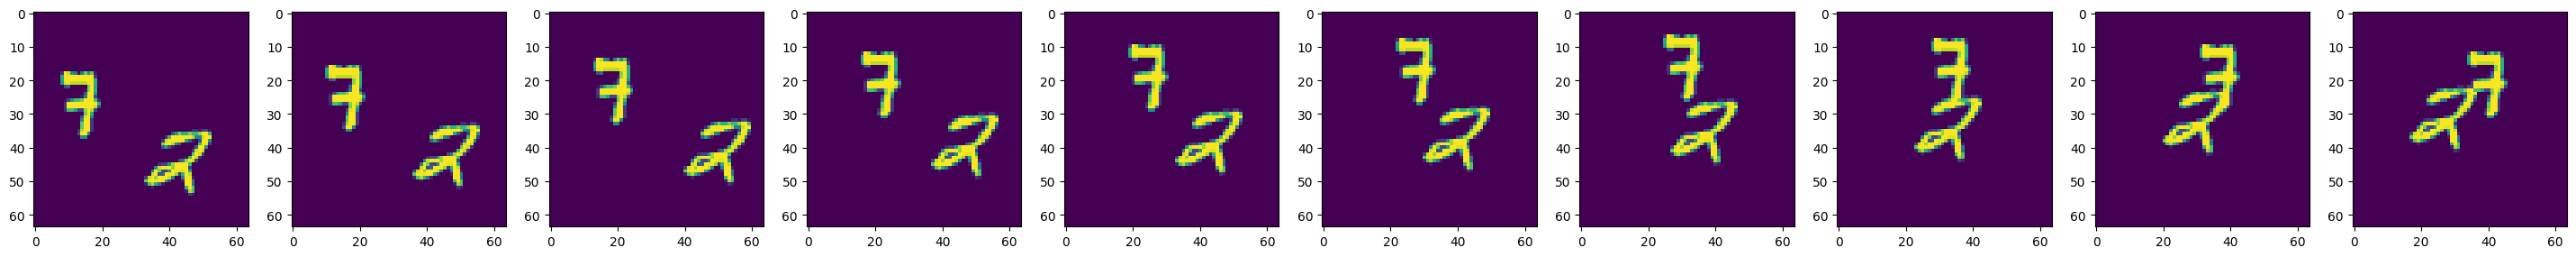

In [11]:
def imshow(past_data):
    num_img = len(past_data)
    fig = plt.figure(figsize=(4*num_img, 4))

    for idx in range(1, num_img+1):
        ax = fig.add_subplot(1, num_img+1, idx)
        ax.imshow(past_data[idx-1])

future_data, past_data = train_set[0]
imshow(past_data)

In [25]:
class Encoder(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=0.1, bidirectional=False)

    def forward(self, x):
        # x: (batch, seq_length, num_channels)
        outputs, (hidden, cell)=  self.lstm(x)
        return (hidden, cell)

class Decoder(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_layers):
        super().__init__()
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=0.1, bidirectional=False)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x, hidden):
        output, (hidden, cell) = self.lstm(x, hidden)
        prediction = self.fc(output)
        return prediction, (hidden, cell)

In [33]:
from torch._higher_order_ops.invoke_leaf_function import reconstruct_original_args
class Seq2Seq(nn.Module):
    def __init__(self, args):
        super().__init__()
        hidden_size = args.hidden_size
        output_size = args.output_size
        input_size = args.input_size
        num_layers = args.num_layers

        self.encoder = Encoder(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers
        )

        self.reconstruct_decoder = Decoder(
            input_size=input_size,
            hidden_size=hidden_size,
            output_size=output_size,
            num_layers=num_layers
        )

        self.predict_decoder = Decoder(
            input_size=input_size,
            hidden_size=hidden_size,
            output_size=output_size,
            num_layers=num_layers
        )

        self.criterion = nn.MSELoss()

    # Loss 출력
    def forward(self, src, trg):
        # src: (batch_size, seq_length, hidden_size)
        # trg: (batch_size, seq_length, hidden_size)
        batch_size, sequence_length, img_size = src.size()

        encoder_hidden = self.encoder(src)

        # Prediction Loss 계산
        predict_output = []
        temp_input = torch.zeros((batch_size, 1, img_size), dtype=torch.float).to(src.device)
        hidden = encoder_hidden
        for t in range(sequence_length):
            temp_input, hidden = self.predict_decoder(temp_input, hidden)
            predict_output.append(temp_input)

        predict_output = torch.cat(predict_output, dim=1)
        predict_loss = self.criterion(predict_output, trg)

        # Reconstruction Loss 계산
        inv_idx = torch.arange(sequence_length - 1, -1, -1).long()
        reconstruct_output = []
        temp_input = torch.zeros((batch_size, 1, img_size), dtype=torch.float).to(src.device)
        hidden = encoder_hidden
        for t in range(sequence_length):
            temp_input, hidden = self.reconstruct_decoder(temp_input, hidden)
            reconstruct_output.append(temp_input)

        reconstruct_output = torch.cat(reconstruct_output, dim=1)
        reconstruct_loss = self.criterion(reconstruct_output, src[:, inv_idx, :])

        return reconstruct_loss, predict_loss


    # 이미지 생성(Prediction)
    def generate(self, src):
        batch_size, sequence_length, img_size = src.size()

        hidden = self.encoder(src)

        outputs = []
        temp_input = torch.zeros((batch_size, 1, img_size), dtype=torch.float).to(src.device)
        for t in range(sequence_length):
            temp_input, hidden = self.predict_decoder(temp_input, hidden)
            outputs.append(temp_input)

        return torch.cat(outputs, dim=1)

    # 이미지 복구(Reconstruction)
    def reconstruct(self, src):
        batch_size, sequence_length, img_size = src.size()

        hidden = self.encoder(src)

        outputs = []
        temp_input = torch.zeros((batch_size, 1, img_size), dtype=torch.float).to(src.device)
        for t in range(sequence_length):
            temp_input, hidden = self.reconstruct_decoder(temp_input, hidden)
            outputs.append(temp_input)

        return torch.cat(outputs, dim=1)


In [34]:
def run(args, model, train_loader, test_loader):
    # optimizer 설정
    optimizer = torch.optim.Adam(model.parameters(), lr=args.learning_rate)

    ## 반복 횟수 Setting
    epochs = tqdm(range(args.max_iter//len(train_loader)+1))

    ## 학습하기
    count = 0
    for epoch in epochs:
        model.train()
        optimizer.zero_grad()
        train_iterator = tqdm(enumerate(train_loader), total=len(train_loader), desc="training")

        for i, batch_data in train_iterator:

            if count > args.max_iter:
                return model
            count += 1

            future_data, past_data = batch_data

            ## 데이터 GPU 설정 및 사이즈 조절
            batch_size = past_data.size(0)
            example_size = past_data.size(1)
            past_data = past_data.view(batch_size, example_size, -1).float().to(args.device)
            future_data = future_data.view(batch_size, example_size, -1).float().to(args.device)

            reconstruct_loss, predict_loss = model(past_data, future_data)

            ## Composite Loss
            loss = reconstruct_loss + predict_loss

            # Backward and optimize
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_iterator.set_postfix({
                "train_loss": float(loss),
            })

        model.eval()
        eval_loss = 0
        test_iterator = tqdm(enumerate(test_loader), total=len(test_loader), desc="testing")
        with torch.no_grad():
            for i, batch_data in test_iterator:
                future_data, past_data = batch_data

                ## 데이터 GPU 설정 및 사이즈 조절
                batch_size = past_data.size(0)
                example_size = past_data.size(1)
                past_data = past_data.view(batch_size, example_size, -1).float().to(args.device)
                future_data = future_data.view(batch_size, example_size, -1).float().to(args.device)

                reconstruct_loss, predict_loss = model(past_data, future_data)

                ## Composite Loss
                loss = reconstruct_loss + predict_loss

                eval_loss += loss.mean().item()

                test_iterator.set_postfix({
                    "eval_loss": float(loss),
                })
        eval_loss = eval_loss / len(test_loader)
        print("Evaluation Score : [{}]".format(eval_loss))
    return model

In [ ]:
model = Seq2Seq(args)
model.to(args.device)

model = run(args, model, train_loader, test_loader)

save_path = 'result'
if not os.path.isdir(save_path):
    os.mkdir(save_path)

model_path = os.path.join(save_path, 'model.bin')
torch.save(model.state_dict(), model_path)

  0%|          | 0/141 [00:00<?, ?it/s]

training:   0%|          | 0/71 [00:00<?, ?it/s]

/tmp/ipykernel_4773/955963626.py:73: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(data[i].numpy(), mode='L')


In [ ]:
from celluloid import Camera

## 에니메이션 데이터 시각화
def animation_show(original_data, generated_data, title, save_path):
    fig = plt.figure(figsize=(8, 4))
    camera = Camera(fig)
    for i in range(len(original_data)):
        ax=fig.add_subplot(121)
        ax.imshow(original_data[i])
        ax.set_title('original')
        ax2=fig.add_subplot(122)
        ax2.imshow(generated_data[i])
        ax2.set_title('generated')
        plt.suptitle(title, fontsize=20)
        camera.snap()

    animation = camera.animate(500, blit=True)

    # .gif 파일로 저장하면 끝!
    animation.save(
        save_path,
        dpi=300,
        savefig_kwargs={
            'frameon': False,
            'pad_inches': 'tight'
        }
    )

## 결과 출력
future_data, past_data = test_set[1]
model.eval()
with torch.no_grad():
    future_data = future_data.to(args.device).view(1, 10, -1).float()
    past_data = past_data.to(args.device).view(1, 10, -1).float()
    outputs = model.generate(past_data)

original_data = future_data.reshape(-1, 64, 64).cpu().squeeze().numpy()
generated_data = outputs.reshape(-1, 64, 64).cpu().squeeze().numpy()

animation_show(original_data, generated_data, "Prediction", 'prediction.gif')